# Experiment: Deep Neural Network (DNN) for Digit Classification

**Aim:** To build a simple 2–3 layer Deep Neural Network using Keras for handwritten digit classification and visualize model layers, activations and loss.

**Dataset:** MNIST handwritten digits (0–9), with images of size 28 × 28 pixels.

## 1. Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Flatten

## 2. Load and display the digit dataset

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


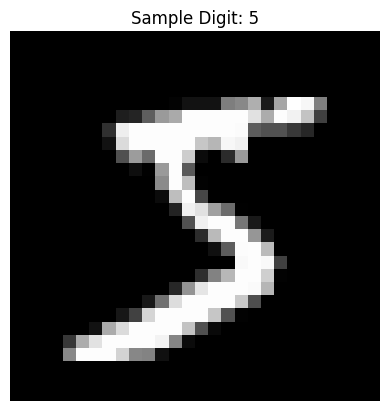

In [2]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

plt.imshow(X_train[0], cmap="gray")
plt.title("Sample Digit: " + str(y_train[0]))
plt.axis("off")
plt.show()

## 3. Normalize the images

In [3]:
# Convert pixel values from 0-255 to 0-1
X_train = X_train / 255.0
X_test = X_test / 255.0

print("Image size:", X_train[0].shape)

Image size: (28, 28)


## 4. Build a simple DNN model

- Flatten: converts the 28 × 28 image into a one-dimensional array.
- Hidden Dense layer: 128 neurons with ReLU activation.
- Output Dense layer: 10 neurons (digits 0–9) with Softmax activation.

In [4]:
model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation="relu"),
    Dense(10, activation="softmax")
])

# Display the model layers
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Compile and train the model

In [5]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.9205 - loss: 0.2775 - val_accuracy: 0.9620 - val_loss: 0.1329
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.9645 - loss: 0.1205 - val_accuracy: 0.9728 - val_loss: 0.0950
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.9751 - loss: 0.0837 - val_accuracy: 0.9670 - val_loss: 0.1066
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9809 - loss: 0.0620 - val_accuracy: 0.9787 - val_loss: 0.0753
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9855 - loss: 0.0471 - val_accuracy: 0.9767 - val_loss: 0.0835


## 6. Visualize training and validation loss

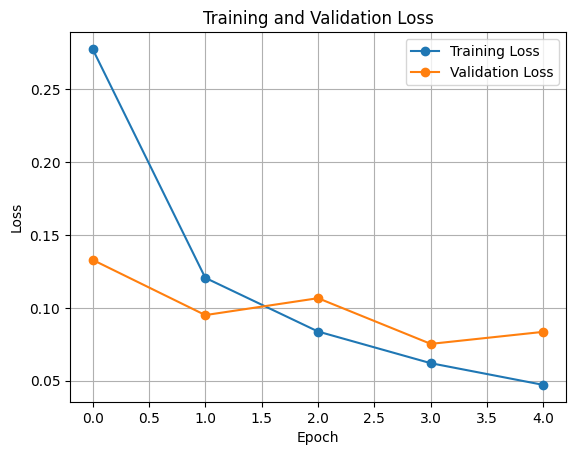

In [6]:
plt.plot(history.history["loss"], marker="o", label="Training Loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

## 7. Visualize training and validation accuracy

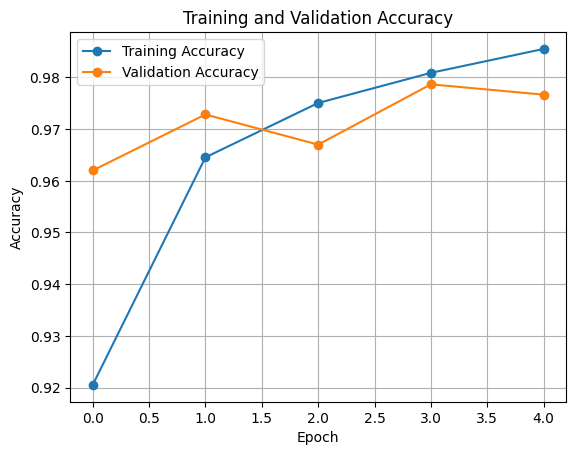

In [7]:
plt.plot(history.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

## 8. Visualize hidden-layer activations

An activation is the output produced by a layer for a given input image. We display the first 16 values from the hidden Dense layer.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step


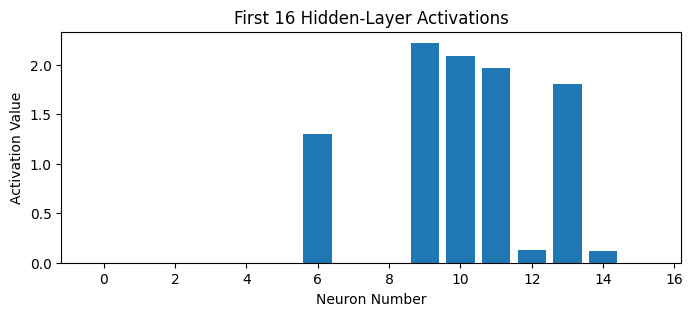

In [8]:
activation_model = Model(
    inputs=model.inputs,
    outputs=model.layers[1].output
)

activations = activation_model.predict(X_test[0:1])

plt.figure(figsize=(8, 3))
plt.bar(range(16), activations[0][:16])
plt.xlabel("Neuron Number")
plt.ylabel("Activation Value")
plt.title("First 16 Hidden-Layer Activations")
plt.show()

## 9. Predict a digit

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step


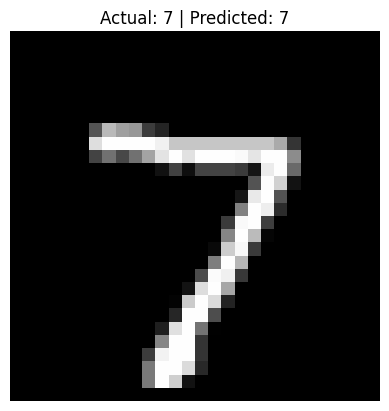

Actual digit: 7
Predicted digit: 7


In [9]:
prediction = model.predict(X_test[0:1])
predicted_digit = np.argmax(prediction)

plt.imshow(X_test[0], cmap="gray")
plt.title("Actual: " + str(y_test[0]) +
          " | Predicted: " + str(predicted_digit))
plt.axis("off")
plt.show()

print("Actual digit:", y_test[0])
print("Predicted digit:", predicted_digit)

## 10. Evaluate the model

In [10]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9766 - loss: 0.0765
Test Loss: 0.0765
Test Accuracy: 97.66 %


## Observations
1. MNIST contains grayscale images of handwritten digits from 0 to 9.
2. The Flatten layer converts each image into a one-dimensional input.
3. The hidden Dense layer learns patterns from the digit images.
4. The output layer has 10 neurons, one for each digit.
5. The loss graph shows how prediction error changes during training.
6. The activation graph displays the output values of selected hidden-layer neurons.
7. Test accuracy indicates how well the model classifies unseen images.

## Result
A simple Deep Neural Network was built using Keras for handwritten digit classification. Model layers, hidden-layer activations, training loss and accuracy were visualized, and the model was evaluated using test data.